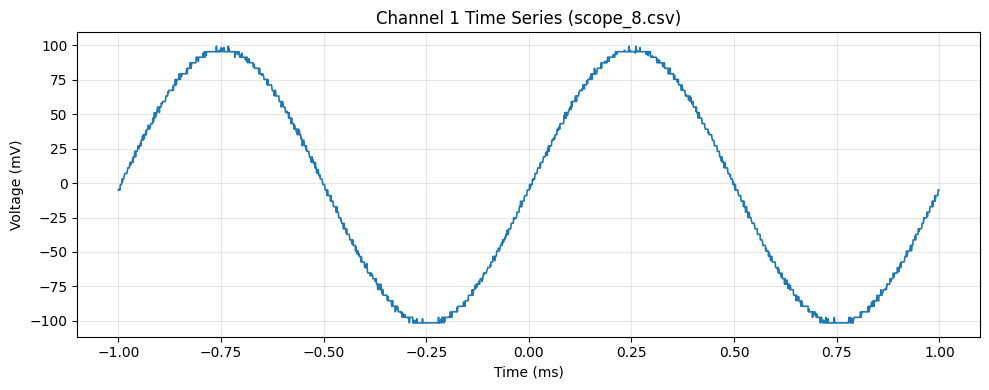

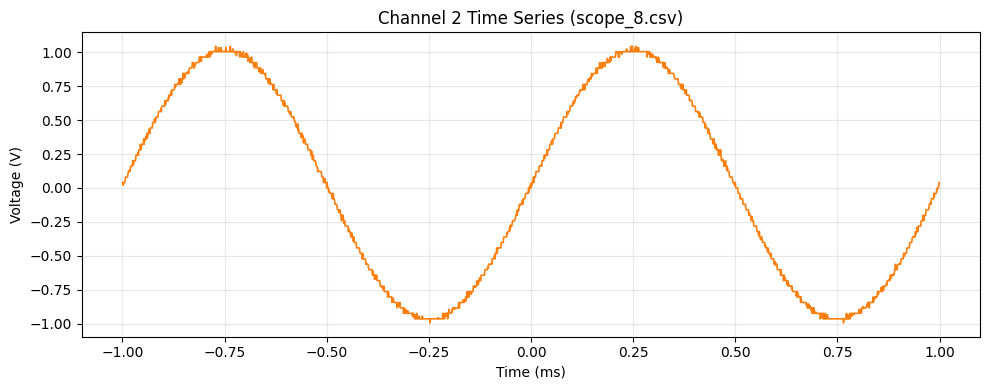

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

with open('scope_8.csv', 'r') as f:
    lines = f.readlines()

end_idx = next((i for i, line in enumerate(lines) if i > 0 and line.startswith('x-axis')), len(lines))

df = pd.read_csv('scope_8.csv', skiprows=1, nrows=end_idx - 2)
df.columns = ['Time_s', 'Ch1_V', 'Ch2_V']

df['Time_ms'] = pd.to_numeric(df['Time_s']) * 1e3
df['Ch1_mV'] = pd.to_numeric(df['Ch1_V']) * 1e3
df['Ch2_V'] = pd.to_numeric(df['Ch2_V'])

plt.figure(figsize=(10, 4))
plt.plot(df['Time_ms'], df['Ch1_mV'], color='#1f77b4', linewidth=1.2)
plt.title('Channel 1 Time Series (scope_8.csv)')
plt.xlabel('Time (ms)')
plt.ylabel('Voltage (mV)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(df['Time_ms'], df['Ch2_V'], color='#ff7f0e', linewidth=1.2)
plt.title('Channel 2 Time Series (scope_8.csv)')
plt.xlabel('Time (ms)')
plt.ylabel('Voltage (V)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Maximum Magnitude: -5.75178 dBV at 1,000.00 Hz (1.000 kHz)
Harmonics found: 18
Computed THD: 1.1198% (-39.02 dB)


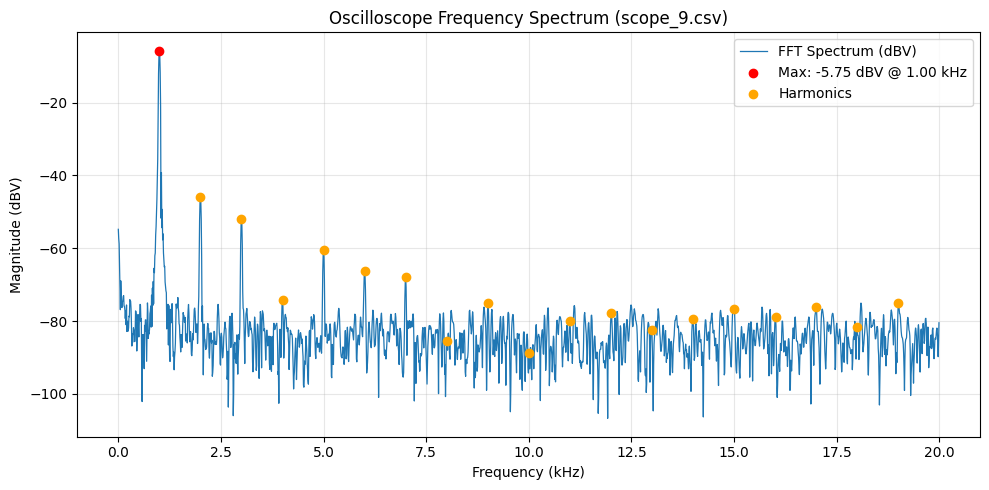

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('f.csv', skiprows=1)
df.columns = ['Frequency_Hz', 'Magnitude_dBV']

df['Frequency_Hz'] = pd.to_numeric(df['Frequency_Hz'], errors='coerce')
df['Magnitude_dBV'] = pd.to_numeric(df['Magnitude_dBV'], errors='coerce')
df_clean = df.dropna().reset_index(drop=True)

freqs = df_clean['Frequency_Hz'].values
mag_dbv = df_clean['Magnitude_dBV'].values

max_idx = np.argmax(mag_dbv)
max_freq = freqs[max_idx]
max_mag = mag_dbv[max_idx]

print(f"Maximum Magnitude: {max_mag:.5f} dBV at {max_freq:,.2f} Hz ({max_freq/1e3:.3f} kHz)")

v_rms = 10 ** (mag_dbv / 20.0)
v1 = v_rms[max_idx]

df_step = np.median(np.diff(freqs))
tolerance = df_step * 1.5
harmonic_voltages = []
harmonic_freqs = []

for n in range(2, 100):
    target_f = n * max_freq
    if target_f > freqs[-1]:
        break
    idx_candidates = np.where(np.abs(freqs - target_f) <= tolerance)[0]
    if len(idx_candidates) > 0:
        best_idx = idx_candidates[np.argmax(mag_dbv[idx_candidates])]
        harmonic_voltages.append(v_rms[best_idx])
        harmonic_freqs.append(freqs[best_idx])

if len(harmonic_voltages) > 0:
    thd_ratio = np.sqrt(np.sum(np.array(harmonic_voltages) ** 2)) / v1
    thd_percent = thd_ratio * 100
    thd_db = 20 * np.log10(thd_ratio)
else:
    thd_percent = 0.0
    thd_db = -np.inf

print(f"Harmonics found: {len(harmonic_voltages)}")
print(f"Computed THD: {thd_percent:.4f}% ({thd_db:.2f} dB)")

plt.figure(figsize=(10, 5))
plt.plot(freqs / 1e3, mag_dbv, color='#1f77b4', linewidth=0.9, label='FFT Spectrum (dBV)')
plt.scatter(max_freq / 1e3, max_mag, color='red', zorder=5, label=f'Max: {max_mag:.2f} dBV @ {max_freq/1e3:.2f} kHz')
if harmonic_freqs:
    harm_dbv = 20 * np.log10(harmonic_voltages)
    plt.scatter(np.array(harmonic_freqs) / 1e3, harm_dbv, color='orange', zorder=5, label='Harmonics')
plt.title('Oscilloscope Frequency Spectrum (scope_9.csv)')
plt.xlabel('Frequency (kHz)')
plt.ylabel('Magnitude (dBV)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('final_fft_1khz.svg', format='svg')
plt.show()


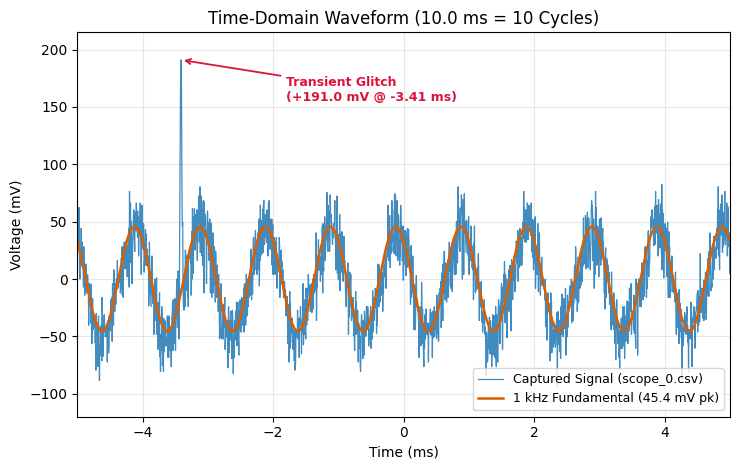

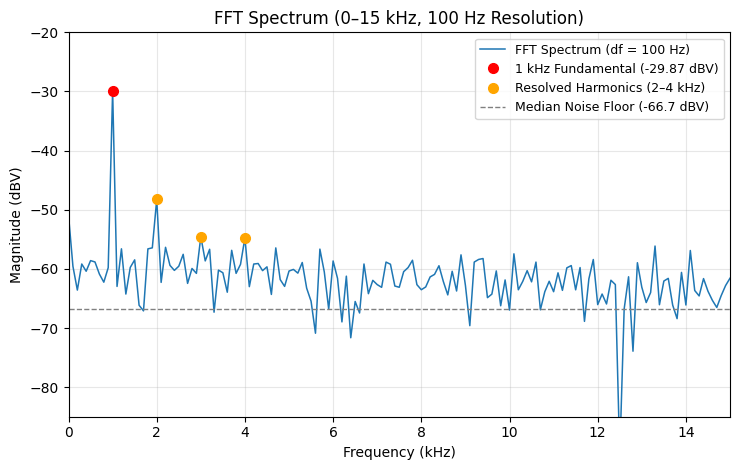

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load Keysight oscilloscope time-domain CSV (skipping the 2 header rows)
df = pd.read_csv('scope_0.csv', skiprows=2, names=['time_s', 'volt']).dropna()
t = df['time_s'].to_numpy(dtype=float)
v = df['volt'].to_numpy(dtype=float)

# 2. Compute exact rectangular-windowed FFT (10.0 ms = 10 cycles -> df = 100 Hz)
N = len(v)
dt = np.mean(np.diff(t))

V_fft = np.fft.rfft(v) / N
freqs_fft = np.fft.rfftfreq(N, d=dt)

amps_peak = np.abs(V_fft) * 2.0
amps_peak[0] = np.abs(V_fft[0])
amps_peak[-1] = np.abs(V_fft[-1])  # Nyquist bin has no conjugate pair

amps_rms = amps_peak / np.sqrt(2.0)
amps_rms[0] = amps_peak[0]
amps_rms[-1] = amps_peak[-1]
dbv_fft = 20.0 * np.log10(amps_rms + 1e-15)

# 3. Reconstruct 1 kHz fundamental (bin 10) and locate the transient glitch
bin_f0 = 10
c_f0 = V_fft[bin_f0] * 2.0
v_fund = np.real(c_f0 * np.exp(1j * 2.0 * np.pi * freqs_fft[bin_f0] * (t - t[0])))

glitch_idx = int(np.argmax(v))
glitch_t_ms = t[glitch_idx] * 1000.0
glitch_v_mv = v[glitch_idx] * 1000.0

# 4. Estimate median noise floor excluding DC and harmonic bins (multiples of 10)
non_harm_mask = np.ones(len(amps_rms), dtype=bool)
non_harm_mask[0] = False
non_harm_mask[10::10] = False
noise_dbv_median = np.median(dbv_fft[non_harm_mask])

# --- Plot 1: Time-Domain Waveform ---
fig1, ax1 = plt.subplots(figsize=(7.5, 4.8))
ax1.plot(t * 1000.0, v * 1000.0, color='#1f77b4', linewidth=0.9, alpha=0.85,
         label='Captured Signal (scope_0.csv)')
ax1.plot(t * 1000.0, v_fund * 1000.0, color='#d95f02', linewidth=1.8,
         label=f'1 kHz Fundamental ({amps_peak[bin_f0] * 1000:.1f} mV pk)')

ax1.annotate(f'Transient Glitch\n(+{glitch_v_mv:.1f} mV @ {glitch_t_ms:.2f} ms)',
             xy=(glitch_t_ms, glitch_v_mv), xytext=(-1.8, 155),
             arrowprops=dict(arrowstyle='->', color='crimson', lw=1.3),
             fontsize=9, fontweight='bold', color='crimson')

ax1.set_title('Time-Domain Waveform (10.0 ms = 10 Cycles)')
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Voltage (mV)')
ax1.set_xlim(-5.0, 5.0)
ax1.set_ylim(-120, 215)
ax1.grid(True, alpha=0.3)
ax1.legend(loc='lower right', fontsize=9)

fig1.tight_layout()
fig1.savefig('time_domain_waveform.svg', format='svg')
plt.show()

# --- Plot 2: FFT Spectrum ---
fig2, ax2 = plt.subplots(figsize=(7.5, 4.8))
mask_15k = freqs_fft <= 15000.0

ax2.plot(freqs_fft[mask_15k] / 1000.0, dbv_fft[mask_15k], color='#1f77b4',
         linewidth=1.1, label='FFT Spectrum (df = 100 Hz)')
ax2.plot(1.0, dbv_fft[bin_f0], 'ro', markersize=7,
         label=f'1 kHz Fundamental ({dbv_fft[bin_f0]:.2f} dBV)')
ax2.plot([2.0, 3.0, 4.0], dbv_fft[[20, 30, 40]], 'o', color='orange',
         markersize=7, label='Resolved Harmonics (2–4 kHz)')
ax2.axhline(noise_dbv_median, color='gray', linestyle='--', linewidth=1.0,
            label=f'Median Noise Floor ({noise_dbv_median:.1f} dBV)')

ax2.set_title('FFT Spectrum (0–15 kHz, 100 Hz Resolution)')
ax2.set_xlabel('Frequency (kHz)')
ax2.set_ylabel('Magnitude (dBV)')
ax2.set_xlim(0, 15)
ax2.set_ylim(-85, -20)
ax2.grid(True, alpha=0.3)
ax2.legend(loc='upper right', fontsize=9)

fig2.tight_layout()
fig2.savefig('fft_spectrum.svg', format='svg')
plt.show()

# Optional: uncomment in Google Colab to download the SVG files automatically
# files.download('time_domain_waveform.svg')
# files.download('fft_spectrum.svg')

Maximum Magnitude: -5.75178 dBV at 1,000.00 Hz (1.000 kHz)
Harmonics found: 18
Computed THD: 1.1198% (-39.02 dB)


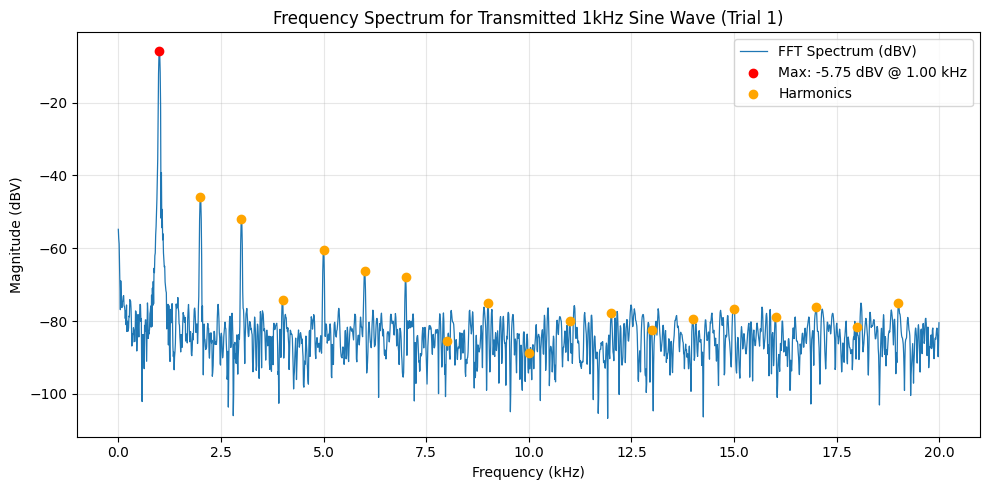

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('f.csv', skiprows=1)
df.columns = ['Frequency_Hz', 'Magnitude_dBV']

df['Frequency_Hz'] = pd.to_numeric(df['Frequency_Hz'], errors='coerce')
df['Magnitude_dBV'] = pd.to_numeric(df['Magnitude_dBV'], errors='coerce')
df_clean = df.dropna().reset_index(drop=True)

freqs = df_clean['Frequency_Hz'].values
mag_dbv = df_clean['Magnitude_dBV'].values

max_idx = np.argmax(mag_dbv)
max_freq = freqs[max_idx]
max_mag = mag_dbv[max_idx]

print(f"Maximum Magnitude: {max_mag:.5f} dBV at {max_freq:,.2f} Hz ({max_freq/1e3:.3f} kHz)")

v_rms = 10 ** (mag_dbv / 20.0)
v1 = v_rms[max_idx]

df_step = np.median(np.diff(freqs))
tolerance = df_step * 1.5
harmonic_voltages = []
harmonic_freqs = []

for n in range(2, 100):
    target_f = n * max_freq
    if target_f > freqs[-1]:
        break
    idx_candidates = np.where(np.abs(freqs - target_f) <= tolerance)[0]
    if len(idx_candidates) > 0:
        best_idx = idx_candidates[np.argmax(mag_dbv[idx_candidates])]
        harmonic_voltages.append(v_rms[best_idx])
        harmonic_freqs.append(freqs[best_idx])

if len(harmonic_voltages) > 0:
    thd_ratio = np.sqrt(np.sum(np.array(harmonic_voltages) ** 2)) / v1
    thd_percent = thd_ratio * 100
    thd_db = 20 * np.log10(thd_ratio)
else:
    thd_percent = 0.0
    thd_db = -np.inf

print(f"Harmonics found: {len(harmonic_voltages)}")
print(f"Computed THD: {thd_percent:.4f}% ({thd_db:.2f} dB)")

plt.figure(figsize=(10, 5))
plt.plot(freqs / 1e3, mag_dbv, color='#1f77b4', linewidth=0.9, label='FFT Spectrum (dBV)')
plt.scatter(max_freq / 1e3, max_mag, color='red', zorder=5, label=f'Max: {max_mag:.2f} dBV @ {max_freq/1e3:.2f} kHz')
if harmonic_freqs:
    harm_dbv = 20 * np.log10(harmonic_voltages)
    plt.scatter(np.array(harmonic_freqs) / 1e3, harm_dbv, color='orange', zorder=5, label='Harmonics')
plt.title('Frequency Spectrum for Transmitted 1kHz Sine Wave (Trial 1)')
plt.xlabel('Frequency (kHz)')
plt.ylabel('Magnitude (dBV)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('final_fft_1khz_trial5.svg', format='svg')
plt.show()


Maximum Magnitude: 0.11353 dBV at 1,000.00 Hz (1.000 kHz)
Harmonics found: 98
Computed THD: 2.1066% (-33.53 dB)


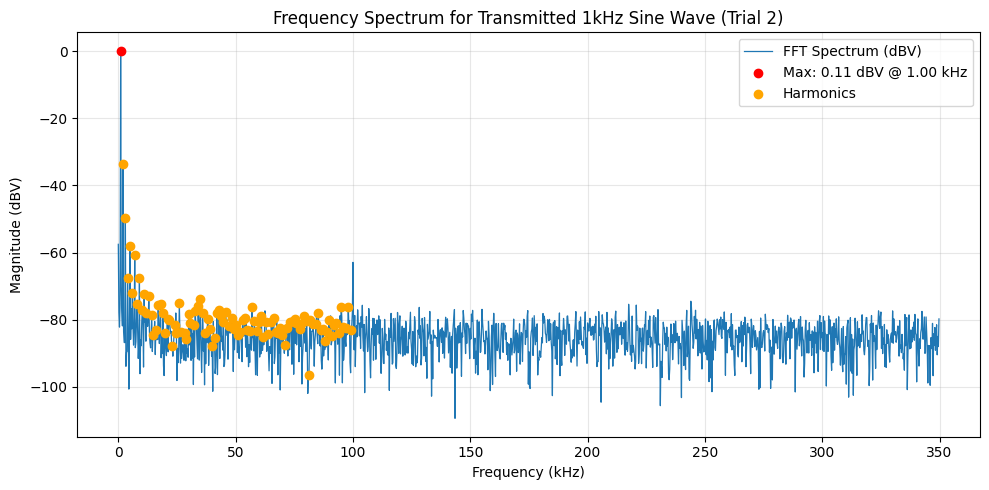

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('f2_1.csv', skiprows=1)
df.columns = ['Frequency_Hz', 'Magnitude_dBV']

df['Frequency_Hz'] = pd.to_numeric(df['Frequency_Hz'], errors='coerce')
df['Magnitude_dBV'] = pd.to_numeric(df['Magnitude_dBV'], errors='coerce')
df_clean = df.dropna().reset_index(drop=True)

freqs = df_clean['Frequency_Hz'].values
mag_dbv = df_clean['Magnitude_dBV'].values

max_idx = np.argmax(mag_dbv)
max_freq = freqs[max_idx]
max_mag = mag_dbv[max_idx]

print(f"Maximum Magnitude: {max_mag:.5f} dBV at {max_freq:,.2f} Hz ({max_freq/1e3:.3f} kHz)")

v_rms = 10 ** (mag_dbv / 20.0)
v1 = v_rms[max_idx]

df_step = np.median(np.diff(freqs))
tolerance = df_step * 1.5
harmonic_voltages = []
harmonic_freqs = []

for n in range(2, 100):
    target_f = n * max_freq
    if target_f > freqs[-1]:
        break
    idx_candidates = np.where(np.abs(freqs - target_f) <= tolerance)[0]
    if len(idx_candidates) > 0:
        best_idx = idx_candidates[np.argmax(mag_dbv[idx_candidates])]
        harmonic_voltages.append(v_rms[best_idx])
        harmonic_freqs.append(freqs[best_idx])

if len(harmonic_voltages) > 0:
    thd_ratio = np.sqrt(np.sum(np.array(harmonic_voltages) ** 2)) / v1
    thd_percent = thd_ratio * 100
    thd_db = 20 * np.log10(thd_ratio)
else:
    thd_percent = 0.0
    thd_db = -np.inf

print(f"Harmonics found: {len(harmonic_voltages)}")
print(f"Computed THD: {thd_percent:.4f}% ({thd_db:.2f} dB)")

plt.figure(figsize=(10, 5))
plt.plot(freqs / 1e3, mag_dbv, color='#1f77b4', linewidth=0.9, label='FFT Spectrum (dBV)')
plt.scatter(max_freq / 1e3, max_mag, color='red', zorder=5, label=f'Max: {max_mag:.2f} dBV @ {max_freq/1e3:.2f} kHz')
if harmonic_freqs:
    harm_dbv = 20 * np.log10(harmonic_voltages)
    plt.scatter(np.array(harmonic_freqs) / 1e3, harm_dbv, color='orange', zorder=5, label='Harmonics')
plt.title('Frequency Spectrum for Transmitted 1kHz Sine Wave (Trial 2)')
plt.xlabel('Frequency (kHz)')
plt.ylabel('Magnitude (dBV)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('final_fft_1khz_trial2.svg', format='svg')
plt.show()


Fundamental f0:             1,000.00 Hz (-5.75 dBV | 515.72 mV_rms)
Wideband Bin Spacing (df):  10.00 Hz/bin
Audio Harmonics found:      18 -> THD_F (from f.csv) = 1.1198% (-39.02 dBc)
PWM Feedthrough (100 kHz):  -74.69 dBc (Total PWM = -74.69 dBc)
Broadband Noise RMS:        96.609 mV_rms (hann ENBW = 1.50)
Wideband THD+N (0-600 kHz): 18.7664% (SINAD = 14.53 dB)


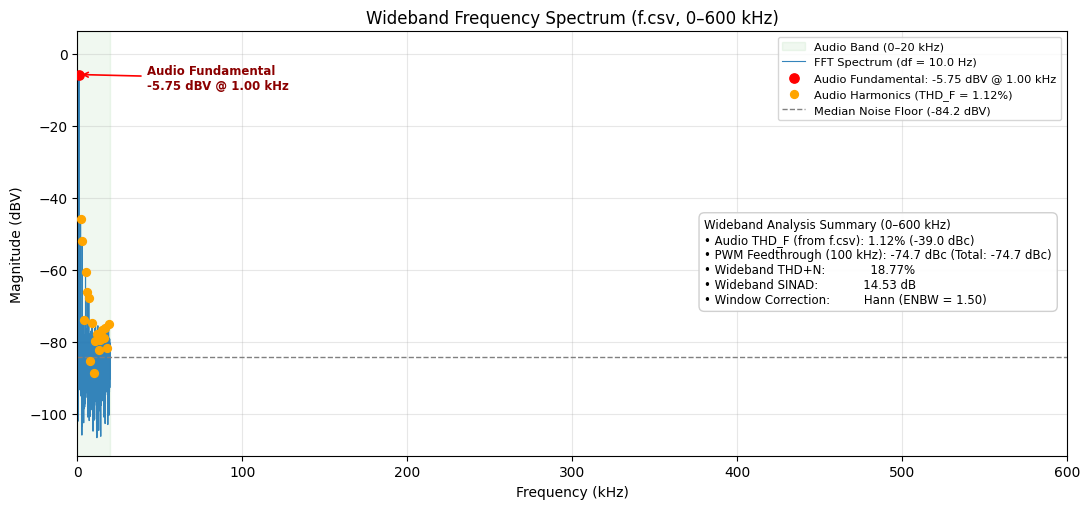

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Optional: uncomment in Google Colab to upload your CSV files
# from google.colab import files
# uploaded = files.upload()

# ==============================================================================
# 1. CONFIGURATION
# ==============================================================================
WIDEBAND_CSV = 'f.csv'   # Your 0-600 kHz FFT CSV filename
AUDIO_CSV = 'f.csv'                 # Optional: your high-res 0-20 kHz CSV for authoritative THD_F (or set to None)
OUTPUT_SVG = 'final_fft_1khz_wideband_trial2.svg'

MAX_FREQ_HZ = 600e3                 # Upper span limit (600 kHz)
PWM_FREQ_HZ = 100e3                 # Nominal PWM carrier frequency (100 kHz)
WINDOW_TYPE = 'hann'                # Scope FFT window: 'hann', 'flattop', 'hamming', 'blackman', 'rect'
PROMINENCE_DB = 6.0                 # Minimum dB above noise floor to identify PWM carrier peaks

# Equivalent Noise Bandwidth (ENBW) & main-lobe guard half-width (in bins)
WINDOW_PARAMS = {
    'rect':     {'enbw': 1.00, 'guard_bins': 1},
    'hann':     {'enbw': 1.50, 'guard_bins': 2},
    'hamming':  {'enbw': 1.36, 'guard_bins': 2},
    'blackman': {'enbw': 1.73, 'guard_bins': 3},
    'flattop':  {'enbw': 3.77, 'guard_bins': 4},
}
enbw = WINDOW_PARAMS[WINDOW_TYPE]['enbw']
guard_bins = WINDOW_PARAMS[WINDOW_TYPE]['guard_bins']


# ==============================================================================
# 2. HELPER FUNCTIONS
# ==============================================================================
def load_fft_csv(filepath, max_hz=None):
    """Loads Keysight FFT CSV (handles 1 or 2 header rows and drops NaN rows)."""
    raw = pd.read_csv(filepath, header=None, usecols=[0, 1], names=['Frequency_Hz', 'Magnitude_dBV'])
    raw['Frequency_Hz'] = pd.to_numeric(raw['Frequency_Hz'], errors='coerce')
    raw['Magnitude_dBV'] = pd.to_numeric(raw['Magnitude_dBV'], errors='coerce')
    clean = raw.dropna().sort_values('Frequency_Hz')
    clean = clean[clean['Frequency_Hz'] >= 0.0]
    if max_hz is not None:
        clean = clean[clean['Frequency_Hz'] <= max_hz]
    return clean.reset_index(drop=True)


def compute_thd_user_method(freqs, mag_dbv, max_harmonic_hz=20e3):
    """Your exact harmonic-summing method, guarded against coarse-bin overlap onto f0."""
    # Search 100 Hz - 5 kHz for audio fundamental so DC or PWM cannot fool argmax
    audio_band = np.where((freqs >= 100.0) & (freqs <= 5000.0))[0]
    max_idx = audio_band[int(np.argmax(mag_dbv[audio_band]))]
    max_freq = freqs[max_idx]
    max_mag = mag_dbv[max_idx]

    v_rms = 10.0 ** (mag_dbv / 20.0)
    v1 = v_rms[max_idx]

    df_step = float(np.median(np.diff(freqs)))
    # Cap tolerance at 0.4 * max_freq so coarse bins on wide spans never reach back to f0
    tolerance = min(df_step * 1.5, 0.4 * max_freq)

    harmonic_voltages = []
    harmonic_freqs = []
    harmonic_indices = []
    used_indices = {int(max_idx)}

    upper_limit = min(freqs[-1], max_harmonic_hz) if max_harmonic_hz is not None else freqs[-1]

    for n in range(2, 100):
        target_f = n * max_freq
        if target_f > upper_limit:
            break
        idx_candidates = np.where(np.abs(freqs - target_f) <= tolerance)[0]
        idx_candidates = np.array([i for i in idx_candidates if int(i) not in used_indices])
        if len(idx_candidates) > 0:
            best_idx = idx_candidates[int(np.argmax(mag_dbv[idx_candidates]))]
            used_indices.add(int(best_idx))
            harmonic_voltages.append(v_rms[best_idx])
            harmonic_freqs.append(freqs[best_idx])
            harmonic_indices.append(int(best_idx))

    if len(harmonic_voltages) > 0:
        thd_ratio = np.sqrt(np.sum(np.array(harmonic_voltages) ** 2)) / v1
        thd_percent = thd_ratio * 100.0
        thd_db = 20.0 * np.log10(thd_ratio)
    else:
        thd_percent = 0.0
        thd_db = -np.inf

    return {
        'max_idx': int(max_idx),
        'max_freq': float(max_freq),
        'max_mag': float(max_mag),
        'v1': float(v1),
        'df_step': df_step,
        'harmonic_freqs': np.array(harmonic_freqs),
        'harmonic_voltages': np.array(harmonic_voltages),
        'harmonic_indices': np.array(harmonic_indices, dtype=int),
        'thd_percent': float(thd_percent),
        'thd_db': float(thd_db),
    }


# ==============================================================================
# 3. LOAD SPECTRA & COMPUTE METRICS
# ==============================================================================
df_wide = load_fft_csv(WIDEBAND_CSV, max_hz=MAX_FREQ_HZ)
freqs = df_wide['Frequency_Hz'].to_numpy(dtype=float)
mag_dbv = df_wide['Magnitude_dBV'].to_numpy(dtype=float)
v_rms = 10.0 ** (mag_dbv / 20.0)

# Audio harmonics on the wideband trace (up to 20 kHz)
res_wide = compute_thd_user_method(freqs, mag_dbv, max_harmonic_hz=20e3)
f0_idx = res_wide['max_idx']
f0 = res_wide['max_freq']
f0_dbv = res_wide['max_mag']
v1 = res_wide['v1']
df_step = res_wide['df_step']

# Use high-res 0-20 kHz CSV for the authoritative THD_F readout if provided
if AUDIO_CSV is not None:
    df_audio = load_fft_csv(AUDIO_CSV, max_hz=20e3)
    res_audio = compute_thd_user_method(
        df_audio['Frequency_Hz'].to_numpy(dtype=float),
        df_audio['Magnitude_dBV'].to_numpy(dtype=float),
        max_harmonic_hz=20e3,
    )
    thd_f_pct = res_audio['thd_percent']
    thd_f_dbc = res_audio['thd_db']
    thd_source_label = f"from {AUDIO_CSV}"
else:
    thd_f_pct = res_wide['thd_percent']
    thd_f_dbc = res_wide['thd_db']
    thd_source_label = "≤20 kHz"

# Detect PWM carrier & harmonics (100, 200, ..., 500 kHz) above median noise floor
noise_floor_dbv = float(np.median(mag_dbv))
pwm_threshold_dbv = noise_floor_dbv + PROMINENCE_DB
pwm_search_hz = min(max(df_step * 1.5, 250.0), 0.4 * PWM_FREQ_HZ)

pwm_freqs, pwm_dbv, pwm_v, pwm_indices = [], [], [], []
for n in range(1, int(MAX_FREQ_HZ // PWM_FREQ_HZ) + 1):
    target_pwm = n * PWM_FREQ_HZ
    if target_pwm > freqs[-1]:
        break
    cands = np.where(np.abs(freqs - target_pwm) <= pwm_search_hz)[0]
    if len(cands) > 0:
        best_p = cands[int(np.argmax(mag_dbv[cands]))]
        if mag_dbv[best_p] >= pwm_threshold_dbv:
            pwm_freqs.append(freqs[best_p])
            pwm_dbv.append(mag_dbv[best_p])
            pwm_v.append(v_rms[best_p])
            pwm_indices.append(int(best_p))

pwm_freqs = np.array(pwm_freqs)
pwm_dbv = np.array(pwm_dbv)
pwm_v = np.array(pwm_v)

if len(pwm_v) > 0:
    pwm_total_dbc = 20.0 * np.log10(np.sqrt(np.sum(pwm_v ** 2)) / v1)
    c1_mask = np.abs(pwm_freqs - PWM_FREQ_HZ) <= pwm_search_hz
    pwm_100k_dbc = float(pwm_dbv[c1_mask][0] - f0_dbv) if np.any(c1_mask) else float(pwm_dbv[0] - f0_dbv)
else:
    idx_100k = int(np.argmin(np.abs(freqs - PWM_FREQ_HZ)))
    pwm_100k_dbc = float(mag_dbv[idx_100k] - f0_dbv)
    pwm_total_dbc = pwm_100k_dbc

# Mask out DC, fundamental, audio harmonics, and PWM peaks (+ guard bins) so window skirts
# are not double-counted in the ENBW-corrected broadband noise sum
tone_mask = np.zeros(len(freqs), dtype=bool)
dc_bins = int(np.ceil(50.0 / df_step)) + guard_bins
tone_mask[:min(dc_bins, len(freqs))] = True

all_tone_indices = [f0_idx] + list(res_wide['harmonic_indices']) + pwm_indices
for idx in all_tone_indices:
    lo = max(0, idx - guard_bins)
    hi = min(len(freqs), idx + guard_bins + 1)
    tone_mask[lo:hi] = True

v_noise_rms = np.sqrt(np.sum(v_rms[~tone_mask] ** 2) / enbw)
v_audio_harm_rms = (thd_f_pct / 100.0) * v1
v_error_rms = np.sqrt(v_audio_harm_rms ** 2 + np.sum(pwm_v ** 2) + v_noise_rms ** 2)

thdn_wide_pct = (v_error_rms / v1) * 100.0
sinad_wide_db = 20.0 * np.log10(v1 / v_error_rms)

print(f"Fundamental f0:             {f0:,.2f} Hz ({f0_dbv:.2f} dBV | {v1*1000:.2f} mV_rms)")
print(f"Wideband Bin Spacing (df):  {df_step:.2f} Hz/bin")
print(f"Audio Harmonics found:      {len(res_wide['harmonic_freqs'])} -> THD_F ({thd_source_label}) = {thd_f_pct:.4f}% ({thd_f_dbc:.2f} dBc)")
print(f"PWM Feedthrough (100 kHz):  {pwm_100k_dbc:.2f} dBc (Total PWM = {pwm_total_dbc:.2f} dBc)")
print(f"Broadband Noise RMS:        {v_noise_rms*1000:.3f} mV_rms ({WINDOW_TYPE} ENBW = {enbw:.2f})")
print(f"Wideband THD+N (0-600 kHz): {thdn_wide_pct:.4f}% (SINAD = {sinad_wide_db:.2f} dB)")

# ==============================================================================
# 4. PLOT WIDEBAND SPECTRUM WITH ANNOTATIONS & SAVE AS SVG
# ==============================================================================
fig, ax = plt.subplots(figsize=(11, 5.2))

ax.axvspan(0, 20, color='#2ca02c', alpha=0.07, label='Audio Band (0–20 kHz)')
ax.plot(freqs / 1e3, mag_dbv, color='#1f77b4', linewidth=0.8, alpha=0.9,
        label=f'FFT Spectrum (df = {df_step:.1f} Hz)')
ax.scatter([f0 / 1e3], [f0_dbv], color='red', s=45, zorder=6,
           label=f'Audio Fundamental: {f0_dbv:.2f} dBV @ {f0/1e3:.2f} kHz')

if len(res_wide['harmonic_freqs']) > 0:
    harm_dbv = 20.0 * np.log10(res_wide['harmonic_voltages'])
    ax.scatter(res_wide['harmonic_freqs'] / 1e3, harm_dbv, color='orange', s=32, zorder=5,
               label=f'Audio Harmonics (THD_F = {thd_f_pct:.2f}%)')

if len(pwm_freqs) > 0:
    ax.scatter(pwm_freqs / 1e3, pwm_dbv, color='#9467bd', marker='D', s=38, zorder=6,
               label=f'PWM Carrier Harmonics ({pwm_100k_dbc:.1f} dBc @ 100 kHz)')

ax.axhline(noise_floor_dbv, color='gray', linestyle='--', linewidth=1.0,
           label=f'Median Noise Floor ({noise_floor_dbv:.1f} dBV)')

ax.annotate(f'Audio Fundamental\n{f0_dbv:.2f} dBV @ {f0/1e3:.2f} kHz',
            xy=(f0 / 1e3, f0_dbv), xytext=(42, f0_dbv - 4),
            arrowprops=dict(arrowstyle='->', color='red', lw=1.2),
            fontsize=8.5, fontweight='bold', color='darkred')

if len(pwm_freqs) > 0:
    idx_100 = int(np.argmin(np.abs(pwm_freqs - PWM_FREQ_HZ)))
    px, py = pwm_freqs[idx_100] / 1e3, pwm_dbv[idx_100]
    ax.annotate(f'100 kHz PWM Carrier\n{py:.2f} dBV ({py - f0_dbv:.1f} dBc)',
                xy=(px, py), xytext=(px + 35, py + 14),
                arrowprops=dict(arrowstyle='->', color='#6a3d9a', lw=1.2),
                fontsize=8.5, fontweight='bold', color='#4a1486')

summary_text = (
    f"Wideband Analysis Summary (0–{MAX_FREQ_HZ/1e3:.0f} kHz)\n"
    f"• Audio THD_F ({thd_source_label}): {thd_f_pct:.2f}% ({thd_f_dbc:.1f} dBc)\n"
    f"• PWM Feedthrough (100 kHz): {pwm_100k_dbc:.1f} dBc (Total: {pwm_total_dbc:.1f} dBc)\n"
    f"• Wideband THD+N:            {thdn_wide_pct:.2f}%\n"
    f"• Wideband SINAD:            {sinad_wide_db:.2f} dB\n"
    f"• Window Correction:         {WINDOW_TYPE.capitalize()} (ENBW = {enbw:.2f})"
)
ax.text(0.985, 0.56, summary_text, transform=ax.transAxes, fontsize=8.5,
        verticalalignment='top', horizontalalignment='right', multialignment='left',
        bbox=dict(boxstyle='round,pad=0.45', facecolor='white', edgecolor='#cccccc', alpha=0.92))

ax.set_title(f'Wideband Frequency Spectrum ({WIDEBAND_CSV}, 0–{MAX_FREQ_HZ/1e3:.0f} kHz)')
ax.set_xlabel('Frequency (kHz)')
ax.set_ylabel('Magnitude (dBV)')
ax.set_xlim(0, MAX_FREQ_HZ / 1e3)
ax.set_ylim(min(np.min(mag_dbv) - 5, -110), max(f0_dbv + 12, 0))
ax.grid(True, alpha=0.3)
ax.legend(loc='upper right', fontsize=8.2)

fig.tight_layout()
fig.savefig(OUTPUT_SVG, format='svg')
plt.show()

# Optional: uncomment in Google Colab to download the SVG automatically
# files.download(OUTPUT_SVG)

In [2]:
import numpy as np
import pandas as pd

# Optional: uncomment in Google Colab to upload your Trial 1 0-20 kHz CSV
# from google.colab import files
# uploaded = files.upload()

# ==============================================================================
# 1. CONFIGURATION
# ==============================================================================
CSV_FILE = 'f3.csv'              # Trial 1 0-20 kHz FFT CSV filename
WINDOW_TYPE = 'hann'            # Scope FFT window: 'hann', 'flattop', 'hamming', 'blackman', 'rect'
LOW_CUTOFF_HZ = 20.0            # Audio band lower limit (20 Hz)
HIGH_CUTOFF_HZ = 20e3           # Audio band upper limit (20 kHz)

WINDOW_PARAMS = {
    'rect':     {'enbw': 1.00, 'guard_bins': 1},
    'hann':     {'enbw': 1.50, 'guard_bins': 2},
    'hamming':  {'enbw': 1.36, 'guard_bins': 2},
    'blackman': {'enbw': 1.73, 'guard_bins': 3},
    'flattop':  {'enbw': 3.77, 'guard_bins': 4},
}
enbw = WINDOW_PARAMS[WINDOW_TYPE]['enbw']
guard_bins = WINDOW_PARAMS[WINDOW_TYPE]['guard_bins']

# ==============================================================================
# 2. LOAD & CLEAN FFT CSV (HANDLES 1 OR 2 HEADER ROWS)
# ==============================================================================
raw = pd.read_csv(CSV_FILE, header=None, usecols=[0, 1], names=['Frequency_Hz', 'Magnitude_dBV'])
raw['Frequency_Hz'] = pd.to_numeric(raw['Frequency_Hz'], errors='coerce')
raw['Magnitude_dBV'] = pd.to_numeric(raw['Magnitude_dBV'], errors='coerce')

df = (
    raw.dropna()
    .sort_values('Frequency_Hz')
    .query('0 <= Frequency_Hz <= @HIGH_CUTOFF_HZ')
    .reset_index(drop=True)
)

freqs = df['Frequency_Hz'].to_numpy(dtype=float)
mag_dbv = df['Magnitude_dBV'].to_numpy(dtype=float)
v_rms = 10.0 ** (mag_dbv / 20.0)
df_step = float(np.median(np.diff(freqs)))

# ==============================================================================
# 3. LOCATE FUNDAMENTAL & HARMONICS (UP TO 20 kHz)
# ==============================================================================
fund_band = np.where((freqs >= 100.0) & (freqs <= 5000.0))[0]
f0_idx = fund_band[int(np.argmax(mag_dbv[fund_band]))]
f0 = freqs[f0_idx]
f0_dbv = mag_dbv[f0_idx]
v1 = v_rms[f0_idx]

tolerance = min(df_step * 1.5, 0.4 * f0)
harmonic_voltages = []
harmonic_indices = []
used_indices = {int(f0_idx)}

for n in range(2, 100):
    target_f = n * f0
    if target_f > HIGH_CUTOFF_HZ:
        break
    cands = np.where(np.abs(freqs - target_f) <= tolerance)[0]
    cands = np.array([i for i in cands if int(i) not in used_indices])
    if len(cands) > 0:
        best_idx = cands[int(np.argmax(mag_dbv[cands]))]
        used_indices.add(int(best_idx))
        harmonic_voltages.append(v_rms[best_idx])
        harmonic_indices.append(int(best_idx))

harmonic_voltages = np.array(harmonic_voltages)
thd_f_ratio = np.sqrt(np.sum(harmonic_voltages ** 2)) / v1
thd_f_pct = thd_f_ratio * 100.0
thd_f_dbc = 20.0 * np.log10(thd_f_ratio)

# ==============================================================================
# 4. COMPUTE AUDIO-BAND THD+N & SINAD (20 Hz - 20 kHz)
# ==============================================================================
# Mask out fundamental and harmonic main lobes (+ guard bins) so window skirts
# are not double-counted in the ENBW-corrected noise integration
tone_mask = np.zeros(len(freqs), dtype=bool)
for idx in [f0_idx] + harmonic_indices:
    lo = max(0, idx - guard_bins)
    hi = min(len(freqs), idx + guard_bins + 1)
    tone_mask[lo:hi] = True

in_audio_band = (freqs >= LOW_CUTOFF_HZ) & (freqs <= HIGH_CUTOFF_HZ)
v_noise_rms = np.sqrt(np.sum(v_rms[in_audio_band & (~tone_mask)] ** 2) / enbw)

v_error_rms = np.sqrt(np.sum(harmonic_voltages ** 2) + v_noise_rms ** 2)
thdn_pct = (v_error_rms / v1) * 100.0
sinad_db = 20.0 * np.log10(v1 / v_error_rms)

# ==============================================================================
# 5. PRINT SUMMARY
# ==============================================================================
print(f"Fundamental f0:                {f0:,.2f} Hz ({f0_dbv:.2f} dBV | {v1*1e3:.2f} mV_rms)")
print(f"Bin Spacing (df):              {df_step:.2f} Hz/bin")
print(f"Audio THD_F (20 Hz - 20 kHz):  {thd_f_pct:.4f}% ({thd_f_dbc:.2f} dBc)")
print(f"In-Band Noise RMS:             {v_noise_rms*1e3:.3f} mV_rms")
print(f"Audio THD+N (20 Hz - 20 kHz):  {thdn_pct:.4f}%")
print(f"Audio SINAD (20 Hz - 20 kHz):  {sinad_db:.2f} dB")

Fundamental f0:                1,000.00 Hz (0.26 dBV | 1029.85 mV_rms)
Bin Spacing (df):              100.00 Hz/bin
Audio THD_F (20 Hz - 20 kHz):  1.7297% (-35.24 dBc)
In-Band Noise RMS:             9.742 mV_rms
Audio THD+N (20 Hz - 20 kHz):  1.9715%
Audio SINAD (20 Hz - 20 kHz):  34.10 dB


Fundamental f0:             1,000.00 Hz (0.26 dBV | 1029.85 mV_rms)
Wideband Bin Spacing (df):  100.00 Hz/bin
Audio Harmonics found:      19 -> THD_F (from f3.csv) = 1.7297% (-35.24 dBc)
PWM Feedthrough (100 kHz):  -61.88 dBc (Total PWM = -61.88 dBc)
Broadband Noise RMS:        10.024 mV_rms (hann ENBW = 1.50)
Wideband THD+N (0-600 kHz): 1.9864% (SINAD = 34.04 dB)


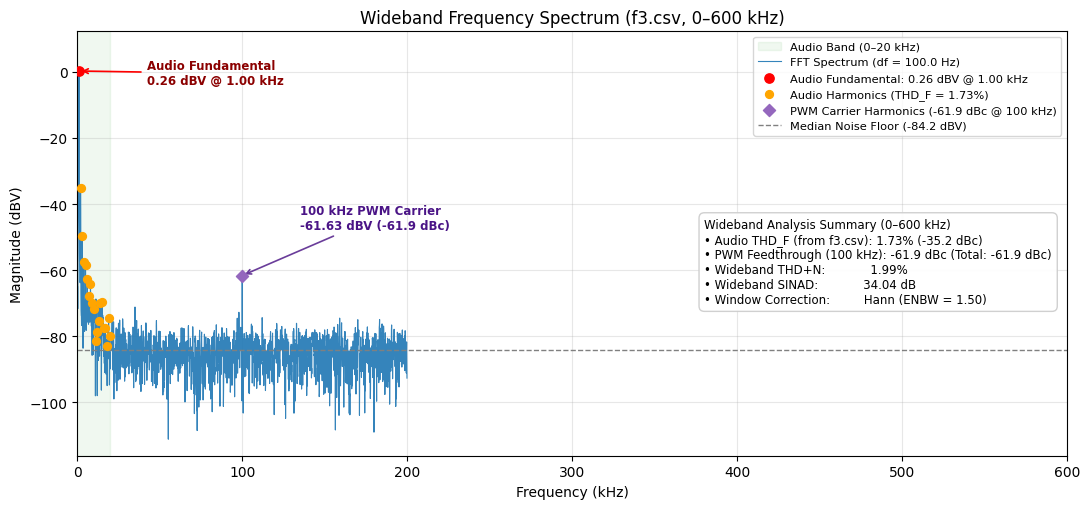

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Optional: uncomment in Google Colab to upload your CSV files
# from google.colab import files
# uploaded = files.upload()

# ==============================================================================
# 1. CONFIGURATION
# ==============================================================================
WIDEBAND_CSV = 'f3.csv'   # Your 0-600 kHz FFT CSV filename
AUDIO_CSV = 'f3.csv'                 # Optional: your high-res 0-20 kHz CSV for authoritative THD_F (or set to None)
OUTPUT_SVG = 'final_fft_1khz_wideband_trial2.svg'

MAX_FREQ_HZ = 600e3                 # Upper span limit (600 kHz)
PWM_FREQ_HZ = 100e3                 # Nominal PWM carrier frequency (100 kHz)
WINDOW_TYPE = 'hann'                # Scope FFT window: 'hann', 'flattop', 'hamming', 'blackman', 'rect'
PROMINENCE_DB = 6.0                 # Minimum dB above noise floor to identify PWM carrier peaks

# Equivalent Noise Bandwidth (ENBW) & main-lobe guard half-width (in bins)
WINDOW_PARAMS = {
    'rect':     {'enbw': 1.00, 'guard_bins': 1},
    'hann':     {'enbw': 1.50, 'guard_bins': 2},
    'hamming':  {'enbw': 1.36, 'guard_bins': 2},
    'blackman': {'enbw': 1.73, 'guard_bins': 3},
    'flattop':  {'enbw': 3.77, 'guard_bins': 4},
}
enbw = WINDOW_PARAMS[WINDOW_TYPE]['enbw']
guard_bins = WINDOW_PARAMS[WINDOW_TYPE]['guard_bins']


# ==============================================================================
# 2. HELPER FUNCTIONS
# ==============================================================================
def load_fft_csv(filepath, max_hz=None):
    """Loads Keysight FFT CSV (handles 1 or 2 header rows and drops NaN rows)."""
    raw = pd.read_csv(filepath, header=None, usecols=[0, 1], names=['Frequency_Hz', 'Magnitude_dBV'])
    raw['Frequency_Hz'] = pd.to_numeric(raw['Frequency_Hz'], errors='coerce')
    raw['Magnitude_dBV'] = pd.to_numeric(raw['Magnitude_dBV'], errors='coerce')
    clean = raw.dropna().sort_values('Frequency_Hz')
    clean = clean[clean['Frequency_Hz'] >= 0.0]
    if max_hz is not None:
        clean = clean[clean['Frequency_Hz'] <= max_hz]
    return clean.reset_index(drop=True)


def compute_thd_user_method(freqs, mag_dbv, max_harmonic_hz=20e3):
    """Your exact harmonic-summing method, guarded against coarse-bin overlap onto f0."""
    # Search 100 Hz - 5 kHz for audio fundamental so DC or PWM cannot fool argmax
    audio_band = np.where((freqs >= 100.0) & (freqs <= 5000.0))[0]
    max_idx = audio_band[int(np.argmax(mag_dbv[audio_band]))]
    max_freq = freqs[max_idx]
    max_mag = mag_dbv[max_idx]

    v_rms = 10.0 ** (mag_dbv / 20.0)
    v1 = v_rms[max_idx]

    df_step = float(np.median(np.diff(freqs)))
    # Cap tolerance at 0.4 * max_freq so coarse bins on wide spans never reach back to f0
    tolerance = min(df_step * 1.5, 0.4 * max_freq)

    harmonic_voltages = []
    harmonic_freqs = []
    harmonic_indices = []
    used_indices = {int(max_idx)}

    upper_limit = min(freqs[-1], max_harmonic_hz) if max_harmonic_hz is not None else freqs[-1]

    for n in range(2, 100):
        target_f = n * max_freq
        if target_f > upper_limit:
            break
        idx_candidates = np.where(np.abs(freqs - target_f) <= tolerance)[0]
        idx_candidates = np.array([i for i in idx_candidates if int(i) not in used_indices])
        if len(idx_candidates) > 0:
            best_idx = idx_candidates[int(np.argmax(mag_dbv[idx_candidates]))]
            used_indices.add(int(best_idx))
            harmonic_voltages.append(v_rms[best_idx])
            harmonic_freqs.append(freqs[best_idx])
            harmonic_indices.append(int(best_idx))

    if len(harmonic_voltages) > 0:
        thd_ratio = np.sqrt(np.sum(np.array(harmonic_voltages) ** 2)) / v1
        thd_percent = thd_ratio * 100.0
        thd_db = 20.0 * np.log10(thd_ratio)
    else:
        thd_percent = 0.0
        thd_db = -np.inf

    return {
        'max_idx': int(max_idx),
        'max_freq': float(max_freq),
        'max_mag': float(max_mag),
        'v1': float(v1),
        'df_step': df_step,
        'harmonic_freqs': np.array(harmonic_freqs),
        'harmonic_voltages': np.array(harmonic_voltages),
        'harmonic_indices': np.array(harmonic_indices, dtype=int),
        'thd_percent': float(thd_percent),
        'thd_db': float(thd_db),
    }


# ==============================================================================
# 3. LOAD SPECTRA & COMPUTE METRICS
# ==============================================================================
df_wide = load_fft_csv(WIDEBAND_CSV, max_hz=MAX_FREQ_HZ)
freqs = df_wide['Frequency_Hz'].to_numpy(dtype=float)
mag_dbv = df_wide['Magnitude_dBV'].to_numpy(dtype=float)
v_rms = 10.0 ** (mag_dbv / 20.0)

# Audio harmonics on the wideband trace (up to 20 kHz)
res_wide = compute_thd_user_method(freqs, mag_dbv, max_harmonic_hz=20e3)
f0_idx = res_wide['max_idx']
f0 = res_wide['max_freq']
f0_dbv = res_wide['max_mag']
v1 = res_wide['v1']
df_step = res_wide['df_step']

# Use high-res 0-20 kHz CSV for the authoritative THD_F readout if provided
if AUDIO_CSV is not None:
    df_audio = load_fft_csv(AUDIO_CSV, max_hz=20e3)
    res_audio = compute_thd_user_method(
        df_audio['Frequency_Hz'].to_numpy(dtype=float),
        df_audio['Magnitude_dBV'].to_numpy(dtype=float),
        max_harmonic_hz=20e3,
    )
    thd_f_pct = res_audio['thd_percent']
    thd_f_dbc = res_audio['thd_db']
    thd_source_label = f"from {AUDIO_CSV}"
else:
    thd_f_pct = res_wide['thd_percent']
    thd_f_dbc = res_wide['thd_db']
    thd_source_label = "≤20 kHz"

# Detect PWM carrier & harmonics (100, 200, ..., 500 kHz) above median noise floor
noise_floor_dbv = float(np.median(mag_dbv))
pwm_threshold_dbv = noise_floor_dbv + PROMINENCE_DB
pwm_search_hz = min(max(df_step * 1.5, 250.0), 0.4 * PWM_FREQ_HZ)

pwm_freqs, pwm_dbv, pwm_v, pwm_indices = [], [], [], []
for n in range(1, int(MAX_FREQ_HZ // PWM_FREQ_HZ) + 1):
    target_pwm = n * PWM_FREQ_HZ
    if target_pwm > freqs[-1]:
        break
    cands = np.where(np.abs(freqs - target_pwm) <= pwm_search_hz)[0]
    if len(cands) > 0:
        best_p = cands[int(np.argmax(mag_dbv[cands]))]
        if mag_dbv[best_p] >= pwm_threshold_dbv:
            pwm_freqs.append(freqs[best_p])
            pwm_dbv.append(mag_dbv[best_p])
            pwm_v.append(v_rms[best_p])
            pwm_indices.append(int(best_p))

pwm_freqs = np.array(pwm_freqs)
pwm_dbv = np.array(pwm_dbv)
pwm_v = np.array(pwm_v)

if len(pwm_v) > 0:
    pwm_total_dbc = 20.0 * np.log10(np.sqrt(np.sum(pwm_v ** 2)) / v1)
    c1_mask = np.abs(pwm_freqs - PWM_FREQ_HZ) <= pwm_search_hz
    pwm_100k_dbc = float(pwm_dbv[c1_mask][0] - f0_dbv) if np.any(c1_mask) else float(pwm_dbv[0] - f0_dbv)
else:
    idx_100k = int(np.argmin(np.abs(freqs - PWM_FREQ_HZ)))
    pwm_100k_dbc = float(mag_dbv[idx_100k] - f0_dbv)
    pwm_total_dbc = pwm_100k_dbc

# Mask out DC, fundamental, audio harmonics, and PWM peaks (+ guard bins) so window skirts
# are not double-counted in the ENBW-corrected broadband noise sum
tone_mask = np.zeros(len(freqs), dtype=bool)
dc_bins = int(np.ceil(50.0 / df_step)) + guard_bins
tone_mask[:min(dc_bins, len(freqs))] = True

all_tone_indices = [f0_idx] + list(res_wide['harmonic_indices']) + pwm_indices
for idx in all_tone_indices:
    lo = max(0, idx - guard_bins)
    hi = min(len(freqs), idx + guard_bins + 1)
    tone_mask[lo:hi] = True

v_noise_rms = np.sqrt(np.sum(v_rms[~tone_mask] ** 2) / enbw)
v_audio_harm_rms = (thd_f_pct / 100.0) * v1
v_error_rms = np.sqrt(v_audio_harm_rms ** 2 + np.sum(pwm_v ** 2) + v_noise_rms ** 2)

thdn_wide_pct = (v_error_rms / v1) * 100.0
sinad_wide_db = 20.0 * np.log10(v1 / v_error_rms)

print(f"Fundamental f0:             {f0:,.2f} Hz ({f0_dbv:.2f} dBV | {v1*1000:.2f} mV_rms)")
print(f"Wideband Bin Spacing (df):  {df_step:.2f} Hz/bin")
print(f"Audio Harmonics found:      {len(res_wide['harmonic_freqs'])} -> THD_F ({thd_source_label}) = {thd_f_pct:.4f}% ({thd_f_dbc:.2f} dBc)")
print(f"PWM Feedthrough (100 kHz):  {pwm_100k_dbc:.2f} dBc (Total PWM = {pwm_total_dbc:.2f} dBc)")
print(f"Broadband Noise RMS:        {v_noise_rms*1000:.3f} mV_rms ({WINDOW_TYPE} ENBW = {enbw:.2f})")
print(f"Wideband THD+N (0-600 kHz): {thdn_wide_pct:.4f}% (SINAD = {sinad_wide_db:.2f} dB)")

# ==============================================================================
# 4. PLOT WIDEBAND SPECTRUM WITH ANNOTATIONS & SAVE AS SVG
# ==============================================================================
fig, ax = plt.subplots(figsize=(11, 5.2))

ax.axvspan(0, 20, color='#2ca02c', alpha=0.07, label='Audio Band (0–20 kHz)')
ax.plot(freqs / 1e3, mag_dbv, color='#1f77b4', linewidth=0.8, alpha=0.9,
        label=f'FFT Spectrum (df = {df_step:.1f} Hz)')
ax.scatter([f0 / 1e3], [f0_dbv], color='red', s=45, zorder=6,
           label=f'Audio Fundamental: {f0_dbv:.2f} dBV @ {f0/1e3:.2f} kHz')

if len(res_wide['harmonic_freqs']) > 0:
    harm_dbv = 20.0 * np.log10(res_wide['harmonic_voltages'])
    ax.scatter(res_wide['harmonic_freqs'] / 1e3, harm_dbv, color='orange', s=32, zorder=5,
               label=f'Audio Harmonics (THD_F = {thd_f_pct:.2f}%)')

if len(pwm_freqs) > 0:
    ax.scatter(pwm_freqs / 1e3, pwm_dbv, color='#9467bd', marker='D', s=38, zorder=6,
               label=f'PWM Carrier Harmonics ({pwm_100k_dbc:.1f} dBc @ 100 kHz)')

ax.axhline(noise_floor_dbv, color='gray', linestyle='--', linewidth=1.0,
           label=f'Median Noise Floor ({noise_floor_dbv:.1f} dBV)')

ax.annotate(f'Audio Fundamental\n{f0_dbv:.2f} dBV @ {f0/1e3:.2f} kHz',
            xy=(f0 / 1e3, f0_dbv), xytext=(42, f0_dbv - 4),
            arrowprops=dict(arrowstyle='->', color='red', lw=1.2),
            fontsize=8.5, fontweight='bold', color='darkred')

if len(pwm_freqs) > 0:
    idx_100 = int(np.argmin(np.abs(pwm_freqs - PWM_FREQ_HZ)))
    px, py = pwm_freqs[idx_100] / 1e3, pwm_dbv[idx_100]
    ax.annotate(f'100 kHz PWM Carrier\n{py:.2f} dBV ({py - f0_dbv:.1f} dBc)',
                xy=(px, py), xytext=(px + 35, py + 14),
                arrowprops=dict(arrowstyle='->', color='#6a3d9a', lw=1.2),
                fontsize=8.5, fontweight='bold', color='#4a1486')

summary_text = (
    f"Wideband Analysis Summary (0–{MAX_FREQ_HZ/1e3:.0f} kHz)\n"
    f"• Audio THD_F ({thd_source_label}): {thd_f_pct:.2f}% ({thd_f_dbc:.1f} dBc)\n"
    f"• PWM Feedthrough (100 kHz): {pwm_100k_dbc:.1f} dBc (Total: {pwm_total_dbc:.1f} dBc)\n"
    f"• Wideband THD+N:            {thdn_wide_pct:.2f}%\n"
    f"• Wideband SINAD:            {sinad_wide_db:.2f} dB\n"
    f"• Window Correction:         {WINDOW_TYPE.capitalize()} (ENBW = {enbw:.2f})"
)
ax.text(0.985, 0.56, summary_text, transform=ax.transAxes, fontsize=8.5,
        verticalalignment='top', horizontalalignment='right', multialignment='left',
        bbox=dict(boxstyle='round,pad=0.45', facecolor='white', edgecolor='#cccccc', alpha=0.92))

ax.set_title(f'Wideband Frequency Spectrum ({WIDEBAND_CSV}, 0–{MAX_FREQ_HZ/1e3:.0f} kHz)')
ax.set_xlabel('Frequency (kHz)')
ax.set_ylabel('Magnitude (dBV)')
ax.set_xlim(0, MAX_FREQ_HZ / 1e3)
ax.set_ylim(min(np.min(mag_dbv) - 5, -110), max(f0_dbv + 12, 0))
ax.grid(True, alpha=0.3)
ax.legend(loc='upper right', fontsize=8.2)

fig.tight_layout()
fig.savefig(OUTPUT_SVG, format='svg')
plt.show()

# Optional: uncomment in Google Colab to download the SVG automatically
# files.download(OUTPUT_SVG)

In [5]:
import numpy as np

# ==============================================================================
# 1. CONFIGURATION
# ==============================================================================
OUTPUT_CSV = "twinkle_edu33212a.csv"
SAMPLE_RATE = 25_000        # 25 kSa/s (14-24 samples/cycle; well under 8 Mpts limit)
ROOT_FREQ_HZ = 1046.50      # C6 Major tonic (1046.5 Hz - 1760.0 Hz; valid root: 500-2970 Hz)
BPM = 132                   # Tempo in beats per minute

# Optional direct upload over USB/LAN via PyVISA
SEND_VIA_VISA = False
VISA_RESOURCE = "USB0::0x2A8D::0x8D01::MY00000000::INSTR"  # Replace with your scope/AWG VISA address
CHANNEL = 1
VPP = 2.0                   # Peak-to-peak output amplitude (Vpp)
LOAD_OHMS = "INF"           # "INF" for High-Z (op-amp/integrator input) or "50" for 50 ohm

# ==============================================================================
# 2. MUSICAL SCALE & MELODY DEFINITION
# ==============================================================================
# Major scale semitone intervals: 1(C6), 2(D6), 3(E6), 4(F6), 5(G6), 6(A6)
SEMITONES = {1: 0, 2: 2, 3: 4, 4: 5, 5: 7, 6: 9}
scale_freqs = {deg: ROOT_FREQ_HZ * (2.0 ** (semi / 12.0)) for deg, semi in SEMITONES.items()}

for deg, f in scale_freqs.items():
    if not (500.0 <= f <= 5000.0):
        raise ValueError(f"Scale degree {deg} ({f:.2f} Hz) falls outside [500 Hz, 5000 Hz].")

# (scale_degree, duration_in_beats)
MELODY = [
    # Twin-kle, twin-kle, lit-tle star
    (1, 1), (1, 1), (5, 1), (5, 1), (6, 1), (6, 1), (5, 2),
    # How I won-der what you are
    (4, 1), (4, 1), (3, 1), (3, 1), (2, 1), (2, 1), (1, 2),
    # Up a-bove the world so high
    (5, 1), (5, 1), (4, 1), (4, 1), (3, 1), (3, 1), (2, 2),
    # Like a dia-mond in the sky
    (5, 1), (5, 1), (4, 1), (4, 1), (3, 1), (3, 1), (2, 2),
    # Twin-kle, twin-kle, lit-tle star
    (1, 1), (1, 1), (5, 1), (5, 1), (6, 1), (6, 1), (5, 2),
    # How I won-der what you are
    (4, 1), (4, 1), (3, 1), (3, 1), (2, 1), (2, 1), (1, 2),
]

# ==============================================================================
# 3. SYNTHESIZE NORMALIZED ARBITRARY WAVEFORM [-1.0, +1.0]
# ==============================================================================
beat_sec = 60.0 / BPM
segments = []

for deg, beats in MELODY:
    freq = scale_freqs[deg]
    n_total = int(round(beats * beat_sec * SAMPLE_RATE))
    # 25 ms gap between notes separates repeated pitches cleanly
    n_rest = min(int(round(0.025 * SAMPLE_RATE)), n_total // 4)
    n_tone = n_total - n_rest

    t = np.arange(n_tone) / SAMPLE_RATE
    tone = np.sin(2.0 * np.pi * freq * t)

    # 12 ms raised-cosine fade-in/out prevents switching clicks
    n_fade = min(int(round(0.012 * SAMPLE_RATE)), n_tone // 3)
    if n_fade > 0:
        fade_in = 0.5 * (1.0 - np.cos(np.pi * np.arange(n_fade) / n_fade))
        tone[:n_fade] *= fade_in
        tone[-n_fade:] *= fade_in[::-1]

    segments.append(tone)
    segments.append(np.zeros(n_rest))

arb_wave = np.concatenate(segments)

# Save single-column normalized CSV for USB drive loading on EDU33212A
np.savetxt(OUTPUT_CSV, arb_wave, fmt="%.6f")
print(f"Saved '{OUTPUT_CSV}' ({len(arb_wave):,} samples, {len(arb_wave)/SAMPLE_RATE:.2f} s @ {SAMPLE_RATE:,} Sa/s)")
print(f"Pitch range: {min(scale_freqs.values()):.2f} Hz to {max(scale_freqs.values()):.2f} Hz")

# ==============================================================================
# 4. OPTIONAL: DIRECT 16-BIT SCPI UPLOAD TO KEYSIGHT EDU33212A
# ==============================================================================
if SEND_VIA_VISA:
    import pyvisa

    rm = pyvisa.ResourceManager()
    awg = rm.open_resource(VISA_RESOURCE)
    awg.timeout = 15000

    # Convert normalized [-1.0, +1.0] to 16-bit signed DAC integers [-32767, +32767]
    dac_samples = np.clip(np.round(arb_wave * 32767), -32767, 32767).astype(np.int16)

    awg.write(f"OUTPut{CHANNEL} OFF")
    awg.write(f"SOURce{CHANNEL}:DATA:VOLatile:CLEar")
    awg.write("FORM:BORD SWAP")  # Little-endian byte order for EDU33212A binary block
    awg.write_binary_values(
        f"SOURce{CHANNEL}:DATA:ARBitrary:DAC TWINKLE,",
        dac_samples,
        datatype="h",
        is_big_endian=False,
    )
    awg.write(f"SOURce{CHANNEL}:FUNCtion:ARBitrary TWINKLE")
    awg.write(f"SOURce{CHANNEL}:FUNCtion ARB")
    awg.write(f"SOURce{CHANNEL}:FUNCtion:ARBitrary:SRATe {SAMPLE_RATE}")
    awg.write(f"OUTPut{CHANNEL}:LOAD {LOAD_OHMS}")
    awg.write(f"SOURce{CHANNEL}:VOLTage {VPP}")
    awg.write(f"SOURce{CHANNEL}:VOLTage:OFFSet 0")
    awg.write(f"OUTPut{CHANNEL} ON")
    print("Uploaded and enabled TWINKLE on Keysight EDU33212A.")

Saved 'twinkle_edu33212a.csv' (545,466 samples, 21.82 s @ 25,000 Sa/s)
Pitch range: 1046.50 Hz to 1760.00 Hz
